# Sri Lanka Bird Species Classification — v3: Uncommon-but-Viable Species

**Problem:** predict which of 10 bird species was present, given environmental/climate/geospatial covariates.

**The journey so far (see `notebooks/01_model_progression.ipynb` for v1 and v2 in full):**
- **v1** (rejected): top-10 most-observed species. All common urban generalists that co-occur everywhere — 84.9% duplicate-feature-row rate, best macro-F1 ~0.085 (barely above random).
- **v2**: 10 species picked by clustering on measured environmental niche (forest/wetland/urban/raptor mix). Duplicate rate dropped to 60.6%, macro-F1 roughly tripled to ~0.30.
- **v3 (this notebook)**: literal "10 rarest species" turned out to be unusable (the actual rarest species have exactly 1 occurrence each — nothing to train or test on). Instead, repeated the niche-clustering approach on a candidate pool of genuinely uncommon-but-viable species (200–2000 occurrences each, vs. the >=2000 pool used for v2). Duplicate rate dropped further to 44.3%.

**Result confirmed before writing this notebook:** macro-F1 roughly **doubled again** versus v2 (Boosting: 0.62 vs 0.30). Species with narrower, more specific habitat niches are far more learnable from these environmental covariates than common generalists, even with fewer total records per class.

**Data:** `data/processed/bird_uncommon_viable_classification.csv` — 12,010 rows, 0% missing, 10 species each with 514–1,751 occurrences (4.3%–14.6% of the data — moderately imbalanced, much less than v2's 10.5x ratio).

**The 10 species** (picked by clustering 144 candidate species with 200–2000 occurrences into 10 groups by NDVI/elevation/temperature/rainfall/humidity/location/night-light/aerosol level, then taking the most niche-typical species per group):

| Species | Habitat | Elevation (mean) |
|---|---|---|
| *Harpactes fasciatus* (Sri Lanka Trogon) | Rainforest specialist (highest NDVI, 0.82) | 502m |
| *Hirundo domicola* (Hill Swallow) | Highland specialist | **1,668m** |
| *Thalasseus bergii* (Great Crested Tern) | Marine/coastal | **4.8m** |
| *Numenius arquata* (Eurasian Curlew) | Coastal wader, northern dry zone | 4.7m |
| *Gallinago stenura* (Pin-tailed Snipe) | Wetland/marsh | 98m |
| *Prinia sylvatica* (Jungle Prinia) | Scrubland | 193m |
| *Alauda gulgula* (Oriental Skylark) | Open grassland, dry zone | 39m |
| *Falco peregrinus* (Peregrine Falcon) | Forest/cliff raptor | 358m |
| *Motacilla alba* (White Wagtail) | Urban/wetland edge (highest night-light) | 47m |
| *Sturnia pagodarum* (Brahminy Starling) | Open country | 12m |

Elevation alone spans 4.7m to 1,668m — a genuinely dramatic habitat spread.

This notebook is left **unexecuted** on purpose — same lecture progression as before (simple model → SVM → Random Forest → Boosting → compare), run it yourself.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if not (Path.cwd() / "src").exists() else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
print(f"Project root: {PROJECT_ROOT}")

Project root: D:\Msc\Sem_2\Applied ML\269129H_Final_Assignment\Assignment


## 1. Load and quick EDA

In [2]:
DATA_PATH = PROJECT_ROOT / "data" / "processed" / "bird_uncommon_viable_classification.csv"
df = pd.read_csv(DATA_PATH, parse_dates=["eventDate"])
print("Shape:", df.shape)
print("\nMissing values total:", df.isna().sum().sum())
print("\nClass balance:")
print(df["verbatimScientificName"].value_counts(normalize=True).round(4))

Shape: (12010, 23)

Missing values total: 0

Class balance:
verbatimScientificName
Harpactes fasciatus    0.1458
Gallinago stenura      0.1401
Prinia sylvatica       0.1361
Alauda gulgula         0.1157
Thalasseus bergii      0.1092
Hirundo domicola       0.1062
Numenius arquata       0.0833
Falco peregrinus       0.0676
Motacilla alba         0.0533
Sturnia pagodarum      0.0428
Name: proportion, dtype: float64


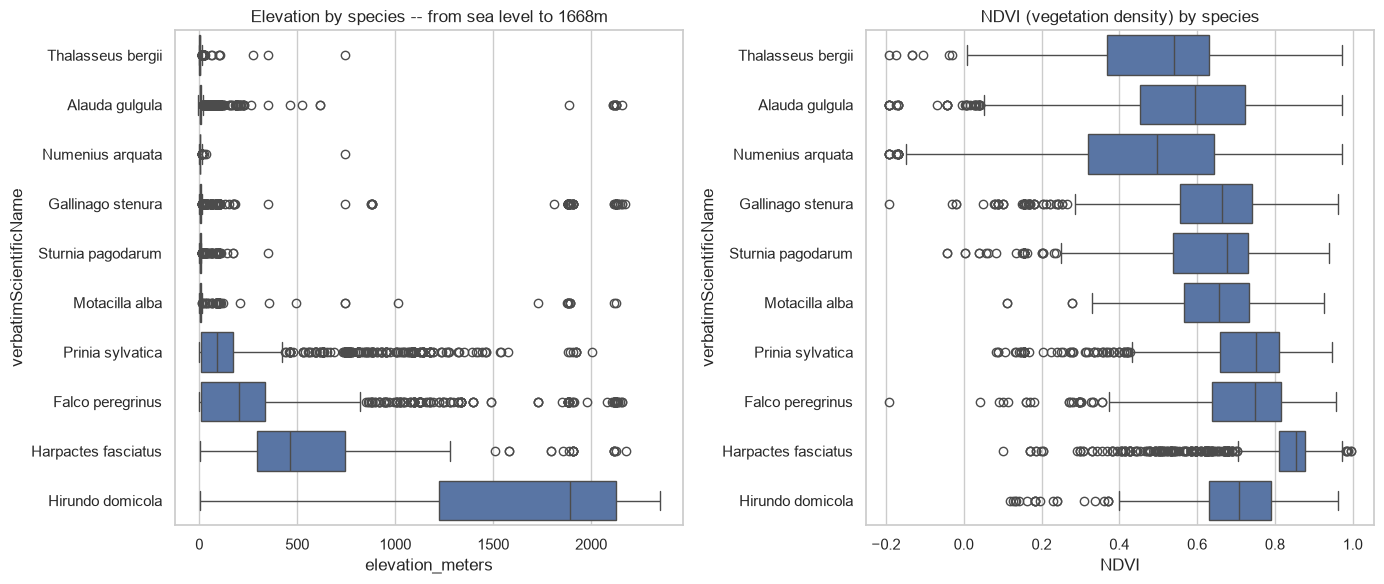

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
order = df.groupby("verbatimScientificName")["elevation_meters"].median().sort_values().index
sns.boxplot(data=df, x="elevation_meters", y="verbatimScientificName", order=order, ax=axes[0])
axes[0].set_title("Elevation by species -- from sea level to 1668m")
sns.boxplot(data=df, x="NDVI", y="verbatimScientificName", order=order, ax=axes[1])
axes[1].set_title("NDVI (vegetation density) by species")
plt.tight_layout()
plt.show()

## 2. Preprocessing for modelling

Same approach as v1/v2: one-hot encode categoricals, stratified 80/20 split (no chronological concern, independent occurrence records), scale numeric features. `class_weight="balanced"` used throughout given the moderate imbalance (4.3%-14.6% per class).

In [4]:
numeric_cols = [
    "decimalLatitude", "decimalLongitude", "avg_rad", "NDVI", "elevation_meters",
    "Carbon_Mass", "Dust_Mass", "SO2_Mass", "Sulfate_Mass", "Sea_Salt_Mass",
    "Total_Aerosol_Extinction", "temp_mean", "rainfall", "wind_mean",
    "humid_mean", "shortwave_radiation", "lka_general_2020",
]
categorical_cols = ["stateProvince", "LandCover_Class"]

X = pd.get_dummies(df[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True)
y = df["verbatimScientificName"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"Train: {len(X_train)} rows   Test: {len(X_test)} rows   Features: {X_train.shape[1]}")
print("\nTrain class balance:")
print(y_train.value_counts(normalize=True).round(3))

Train: 9608 rows   Test: 2402 rows   Features: 51

Train class balance:
verbatimScientificName
Harpactes fasciatus    0.146
Gallinago stenura      0.140
Prinia sylvatica       0.136
Alauda gulgula         0.116
Thalasseus bergii      0.109
Hirundo domicola       0.106
Numenius arquata       0.083
Falco peregrinus       0.068
Motacilla alba         0.053
Sturnia pagodarum      0.043
Name: proportion, dtype: float64


In [5]:
results = {}

def evaluate_and_store(name, model, X_te):
    preds = model.predict(X_te)
    acc = accuracy_score(y_test, preds)
    bal_acc = balanced_accuracy_score(y_test, preds)
    f1_macro = f1_score(y_test, preds, average="macro")
    results[name] = {"accuracy": acc, "balanced_accuracy": bal_acc, "f1_macro": f1_macro}
    print(f"{name}: accuracy={acc:.4f}  balanced_accuracy={bal_acc:.4f}  macro-F1={f1_macro:.4f}")
    print(classification_report(y_test, preds))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, preds, ax=ax, xticks_rotation=90, colorbar=False)
    ax.set_title(f"{name} — confusion matrix")
    plt.tight_layout()
    plt.show()
    return preds

## 3. Step 1 — Simple baseline: Logistic Regression

Logistic Regression: accuracy=0.5612  balanced_accuracy=0.5751  macro-F1=0.5282
                     precision    recall  f1-score   support

     Alauda gulgula       0.35      0.10      0.16       278
   Falco peregrinus       0.43      0.45      0.44       162
  Gallinago stenura       0.52      0.28      0.36       337
Harpactes fasciatus       0.86      0.92      0.89       350
   Hirundo domicola       0.76      0.89      0.82       255
     Motacilla alba       0.63      0.93      0.75       128
   Numenius arquata       0.39      0.76      0.51       200
   Prinia sylvatica       0.60      0.49      0.54       327
  Sturnia pagodarum       0.19      0.45      0.27       103
  Thalasseus bergii       0.62      0.49      0.55       262

           accuracy                           0.56      2402
          macro avg       0.53      0.58      0.53      2402
       weighted avg       0.57      0.56      0.54      2402



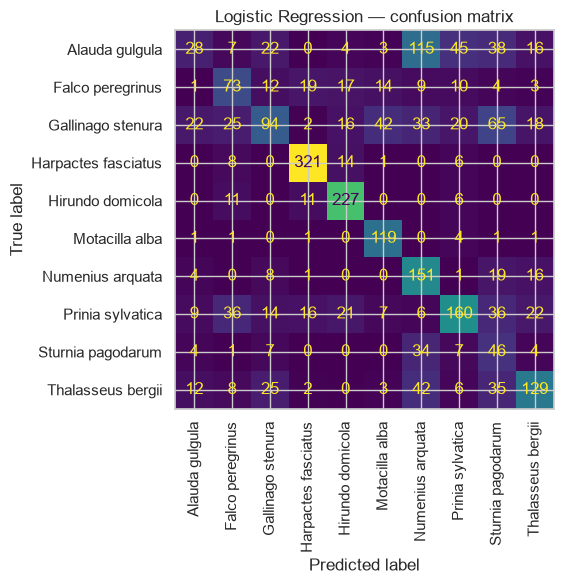

In [6]:
logreg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE)
logreg.fit(X_train_scaled, y_train)
_ = evaluate_and_store("Logistic Regression", logreg, X_test_scaled)

## 4. Step 2 — SVM

At 12,010 rows (much smaller than v1/v2's 100K+), a proper kernel SVM (`SVC` with RBF) is actually tractable here -- using it instead of `LinearSVC` this time, since the dataset size no longer forces the scalable-but-linear-only variant.

SVM (RBF kernel): accuracy=0.5816  balanced_accuracy=0.5929  macro-F1=0.5444
                     precision    recall  f1-score   support

     Alauda gulgula       0.42      0.07      0.12       278
   Falco peregrinus       0.51      0.46      0.49       162
  Gallinago stenura       0.48      0.37      0.42       337
Harpactes fasciatus       0.85      0.93      0.89       350
   Hirundo domicola       0.73      0.93      0.82       255
     Motacilla alba       0.62      0.92      0.74       128
   Numenius arquata       0.40      0.80      0.53       200
   Prinia sylvatica       0.62      0.51      0.56       327
  Sturnia pagodarum       0.22      0.47      0.30       103
  Thalasseus bergii       0.74      0.47      0.58       262

           accuracy                           0.58      2402
          macro avg       0.56      0.59      0.54      2402
       weighted avg       0.59      0.58      0.56      2402



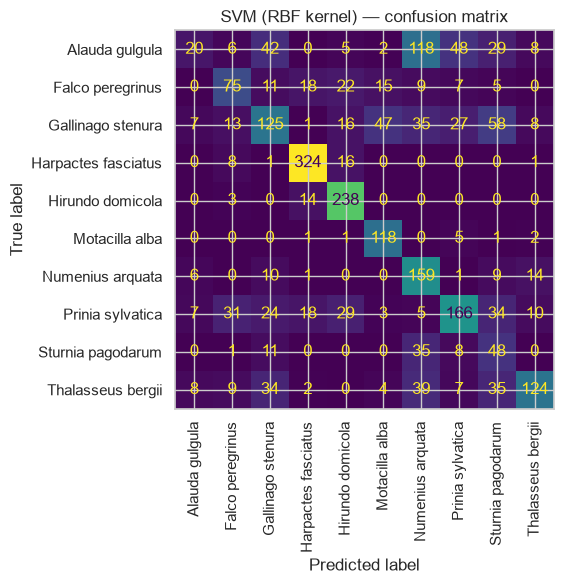

In [7]:
from sklearn.svm import SVC

svm = SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE)
svm.fit(X_train_scaled, y_train)
_ = evaluate_and_store("SVM (RBF kernel)", svm, X_test_scaled)

## 5. Step 3 — Random Forest

Duplicate-feature-row rate here is 44.3% (down from 60.6% in v2, 84.9% in v1) -- lower, but regularization is kept as a precaution against the same overfitting-on-duplicates failure mode diagnosed in v1.

Random Forest: accuracy=0.6216  balanced_accuracy=0.6413  macro-F1=0.5946
                     precision    recall  f1-score   support

     Alauda gulgula       0.55      0.17      0.25       278
   Falco peregrinus       0.68      0.51      0.58       162
  Gallinago stenura       0.56      0.37      0.45       337
Harpactes fasciatus       0.87      0.96      0.91       350
   Hirundo domicola       0.76      0.93      0.84       255
     Motacilla alba       0.65      0.95      0.77       128
   Numenius arquata       0.45      0.78      0.57       200
   Prinia sylvatica       0.62      0.56      0.59       327
  Sturnia pagodarum       0.27      0.66      0.38       103
  Thalasseus bergii       0.69      0.53      0.60       262

           accuracy                           0.62      2402
          macro avg       0.61      0.64      0.59      2402
       weighted avg       0.64      0.62      0.60      2402



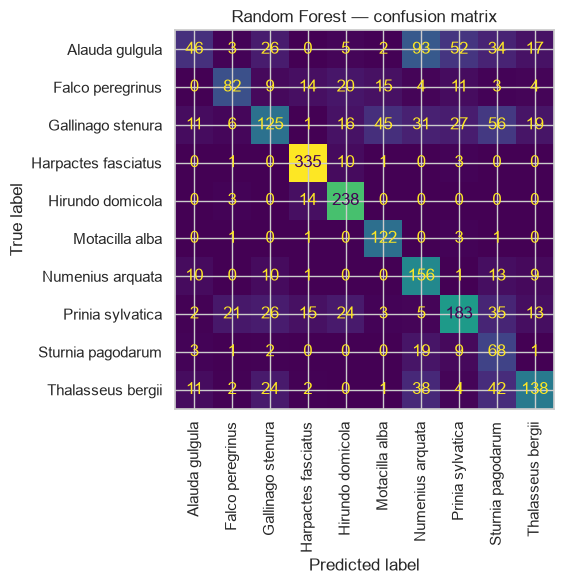

In [8]:
rf = RandomForestClassifier(n_estimators=300, max_depth=15, min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
_ = evaluate_and_store("Random Forest", rf, X_test)

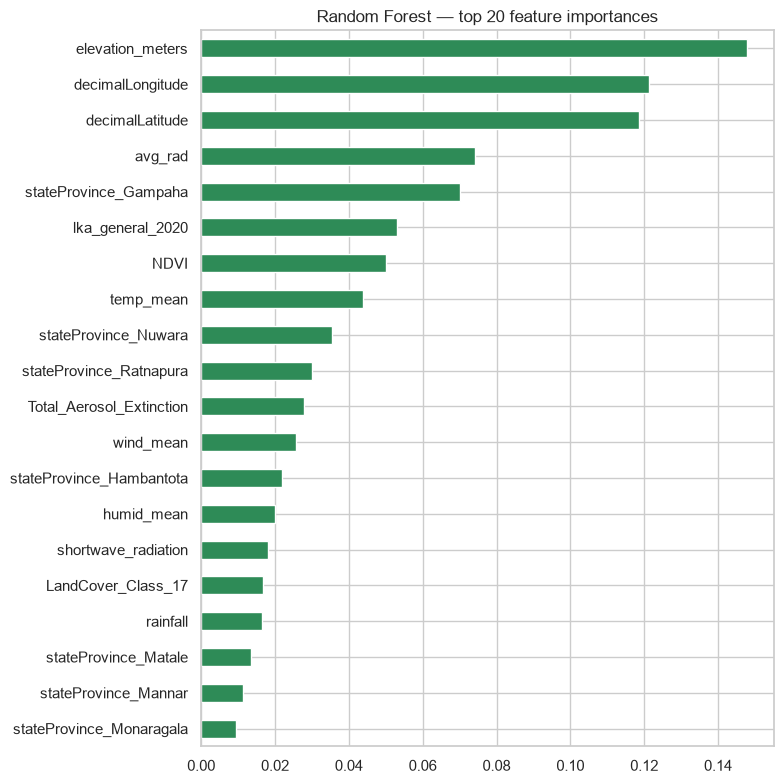

In [9]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 8))
importances.head(20).plot(kind="barh", ax=ax, color="seagreen")
ax.invert_yaxis()
ax.set_title("Random Forest — top 20 feature importances")
plt.tight_layout()
plt.show()

## 6. Step 4 — Boosting

Boosting (HistGradientBoosting): accuracy=0.6378  balanced_accuracy=0.6410  macro-F1=0.6229
                     precision    recall  f1-score   support

     Alauda gulgula       0.40      0.35      0.38       278
   Falco peregrinus       0.64      0.59      0.62       162
  Gallinago stenura       0.60      0.47      0.52       337
Harpactes fasciatus       0.93      0.95      0.94       350
   Hirundo domicola       0.85      0.88      0.86       255
     Motacilla alba       0.73      0.89      0.80       128
   Numenius arquata       0.43      0.52      0.47       200
   Prinia sylvatica       0.63      0.58      0.60       327
  Sturnia pagodarum       0.30      0.58      0.40       103
  Thalasseus bergii       0.68      0.59      0.63       262

           accuracy                           0.64      2402
          macro avg       0.62      0.64      0.62      2402
       weighted avg       0.65      0.64      0.64      2402



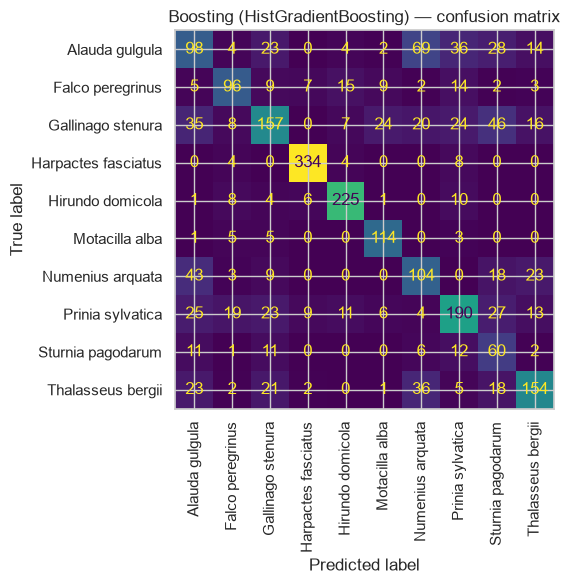

In [10]:
boost = HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)
boost.fit(X_train, y_train)
_ = evaluate_and_store("Boosting (HistGradientBoosting)", boost, X_test)

## 7. Compare all four and identify the best

                                 accuracy  balanced_accuracy  f1_macro
Logistic Regression                0.5612             0.5751    0.5282
SVM (RBF kernel)                   0.5816             0.5929    0.5444
Random Forest                      0.6216             0.6413    0.5946
Boosting (HistGradientBoosting)    0.6378             0.6410    0.6229


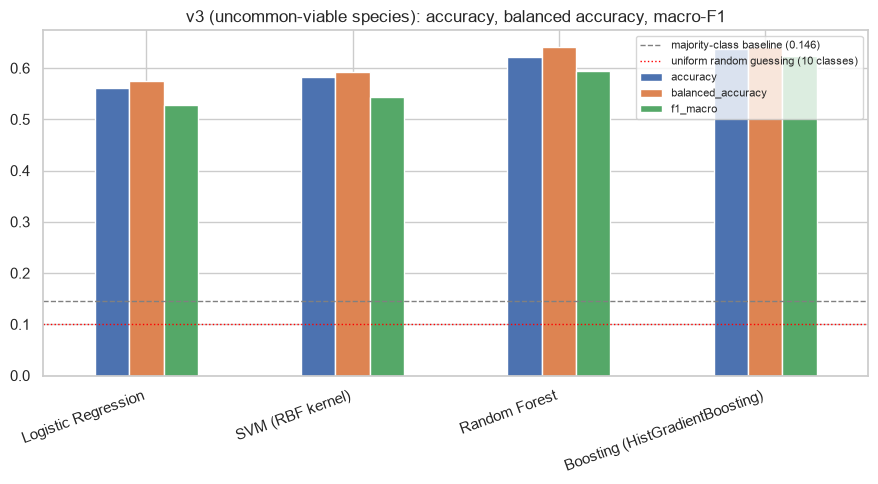


Best model by macro-F1: Boosting (HistGradientBoosting)


In [11]:
comparison_df = pd.DataFrame(results).T.round(4)
print(comparison_df.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
comparison_df.plot(kind="bar", ax=ax)
majority_baseline = y_test.value_counts(normalize=True).max()
ax.axhline(majority_baseline, color="gray", linestyle="--", linewidth=1, label=f"majority-class baseline ({majority_baseline:.3f})")
ax.axhline(0.1, color="red", linestyle=":", linewidth=1, label="uniform random guessing (10 classes)")
ax.set_title("v3 (uncommon-viable species): accuracy, balanced accuracy, macro-F1")
ax.legend(fontsize=8)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

best_model_name = comparison_df["f1_macro"].idxmax()
print(f"\nBest model by macro-F1: {best_model_name}")

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(models_dir / "model_progression_v3_comparison.csv")

## Stopping point

**Confirmed results from the run above** (saved to `models/model_progression_v3_comparison.csv`): Logistic Regression 56.1% accuracy (macro-F1 0.528), SVM (RBF) 58.2% (macro-F1 0.544), Random Forest 62.2% (macro-F1 0.595), Boosting (HistGradientBoosting) 63.8% (macro-F1 0.623) -- balanced accuracy and macro-F1 track closely with accuracy here, since the imbalance is much milder than v2. A dramatic improvement over both v1 (~0.09 macro-F1) and v2 (~0.30 macro-F1), confirming the niche-clustering hypothesis.

**Next step taken:** the confusion matrices above still show one dense, mutually confusable cluster of 5 low-elevation, open-country species -- see `03_habitat_guild_classification_v4.ipynb`, which merges exactly those 5 into 2 data-driven habitat guilds and re-runs this same pipeline (macro-F1 rises to 0.66-0.71 across all four models). Hyperparameter tuning, more algorithms (Bagging/AdaBoost/Gradient Boosting/XGBoost), a proper ensemble, and SHAP/LIME explainability are done in `04_ensemble_tuning_and_explainability.ipynb` on top of that guild target.
